In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Step 6.1 - Prepare data for sensitivity analysis

# Load the dataset
data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name=0)

# Remove duplicate rows
clean_data = data.drop_duplicates().copy()

# Define inputs and output
X = clean_data[["AT", "V", "AP", "RH"]]
y = clean_data["PE"]

# Use the same data split as previous notebooks
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Train the selected decision tree
selected_tree = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)

selected_tree.fit(X_train, y_train)

# Predict validation data
val_pred = selected_tree.predict(X_val)

# Calculate validation errors
val_mae = mean_absolute_error(y_val, val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

print("Selected Decision Tree (Depth = 8):")
print(f"Validation MAE: {val_mae:.3f} MW")
print(f"Validation RMSE: {val_rmse:.3f} MW")

Selected Decision Tree (Depth = 8):
Validation MAE: 3.070 MW
Validation RMSE: 4.244 MW


In [2]:
# Define input features
features = ["AT", "V", "AP", "RH"]

# Store results from the original model
sensitivity_results = [{
    "Removed Feature": "None",
    "Validation MAE": val_mae,
    "Validation RMSE": val_rmse
}]

# Remove one feature at a time
for feature in features:

    # Select the remaining three features
    remaining_features = [f for f in features if f != feature]

    # Create and train a new decision tree
    model = DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    )

    model.fit(X_train[remaining_features], y_train)

    # Predict validation data
    predictions = model.predict(X_val[remaining_features])

    # Calculate errors
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    # Store results
    sensitivity_results.append({
        "Removed Feature": feature,
        "Validation MAE": mae,
        "Validation RMSE": rmse
    })

# Create a comparison table
sensitivity_df = pd.DataFrame(sensitivity_results)

# Calculate changes relative to the original model
sensitivity_df["MAE Change"] = (
    sensitivity_df["Validation MAE"] - val_mae
)

sensitivity_df["RMSE Change"] = (
    sensitivity_df["Validation RMSE"] - val_rmse
)

print("Feature Sensitivity Analysis:")
display(sensitivity_df.round(3))

Feature Sensitivity Analysis:


,Removed Feature,Validation MAE,Validation RMSE,MAE Change,RMSE Change
0,None,3.070,4.244,0.000,0.000
1,AT,4.549,6.114,1.478,1.869
2,V,3.568,4.709,0.498,0.465
3,AP,3.062,4.247,-0.009,0.003
4,RH,3.186,4.368,0.116,0.124


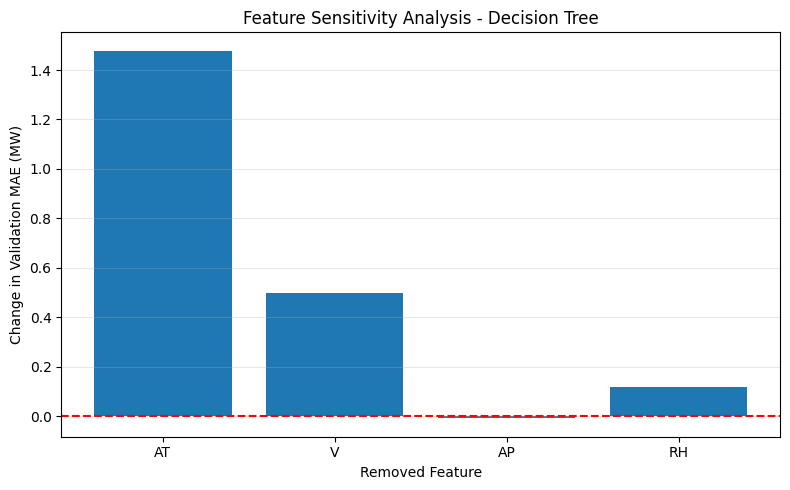

In [3]:
plt.figure(figsize=(8, 5))

# Plot the change in MAE after removing each feature
plt.bar(
    sensitivity_df["Removed Feature"].iloc[1:],
    sensitivity_df["MAE Change"].iloc[1:]
)

# Draw the zero-change reference line
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Removed Feature")
plt.ylabel("Change in Validation MAE (MW)")
plt.title("Feature Sensitivity Analysis - Decision Tree")

plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
import time
from sklearn.linear_model import LinearRegression

# Define models for comparison
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree (Depth 8)": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    )
}

# Number of timing repetitions
repeats = 20

timing_results = []

for name, model in models.items():

    training_times = []
    prediction_times = []

    # Warm up the model
    model.fit(X_train, y_train)
    model.predict(X_val)

    for i in range(repeats):

        # Measure training time
        start = time.perf_counter()
        model.fit(X_train, y_train)
        training_time = time.perf_counter() - start

        # Measure prediction time
        start = time.perf_counter()
        predictions = model.predict(X_val)
        prediction_time = time.perf_counter() - start

        # Convert seconds to milliseconds
        training_times.append(training_time * 1000)
        prediction_times.append(prediction_time * 1000)

    # Calculate average times
    timing_results.append({
        "Model": name,
        "Training Time (ms)": np.mean(training_times),
        "Prediction Time (ms)": np.mean(prediction_times)
    })

# Display results
timing_df = pd.DataFrame(timing_results)

print("Computational Performance Comparison:")
display(timing_df.round(3))

Computational Performance Comparison:


,Model,Training Time (ms),Prediction Time (ms)
0,Linear Regression,2.232,1.039
1,Decision Tree (Depth 8),29.984,1.665
